# **MÓDULO 13**
# Projeto - Fundamentos da Descoberta de Dados

Nesse projeto trabalharemos com a base de dados de produtos de um supermercado do Chile.
A ideia é que vocês apliquem os conceitos estatísticos vistos no último módulo, mais os conceitos de visualizações de dados através de gráficos e finalizem publicando no seu github!

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style='whitegrid')

Faça a leitura dos dados do arquivo CSV:


Altere o código abaixo de acordo com seu diretório.

In [2]:
# O arquivo baixado usa vírgula como separador
df = pd.read_csv("MODULO7_PROJETOFINAL_BASE_SUPERMERCADO.csv", delimiter=',')

df.head(10)

,title,Marca,Preco_Normal,Preco_Desconto,Preco_Anterior,Desconto,Categoria
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788,0,0,0,lacteos
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228,0,0,0,lacteos
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228,0,0,0,lacteos
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228,0,0,0,lacteos
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,17988,0,0,0,lacteos
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,17388,0,0,0,lacteos
8,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,17388,0,0,0,lacteos
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,17388,0,0,0,lacteos


Os campos do nosso dataframe são:

**Title:** Nome do produto.


**Marca:** A marca do produto.


**Preco_Normal:** O preço em que o produto costuma ser vendido quando não há desconto.


**Preco_Desconto:** O preço vendido após o desconto ser aplicado.


**Preco_Anterior:** Preço em que era comercializado o produto antes do desconto aplicado.


**Desconto:** Total de desconto aplicado.






As colunas que aparecem com valores 0 são para os produtos onde não tivemos descontos aplicados.


As categorias estão em espanhol!

In [3]:
# Visão geral: dimensões, tipos e nulos
print('Linhas e colunas:', df.shape)
print('\nProdutos por categoria:')
print(df['Categoria'].value_counts())
print('\nValores nulos:', df.isnull().sum().sum())
print('Produtos com Preco_Normal = 0 (estão com desconto):', (df['Preco_Normal'] == 0).sum())

Linhas e colunas: (1107, 7)

Produtos por categoria:
Categoria
lacteos                       447
belleza-y-cuidado-personal    239
congelados                    235
verduras                       64
instantaneos-y-sopas           57
comidas-preparadas             46
frutas                         19
Name: count, dtype: int64

Valores nulos: 0
Produtos com Preco_Normal = 0 (estão com desconto): 294


# 1 - Traga a média e a mediana dos preços - coluna Preco_Normal - por categoria de produto.
# Identifique as categorias que parecem ter um valor de média abaixo ou acima da mediana.

In [4]:
# Média do Preco_Normal por categoria
media = df.groupby('Categoria')['Preco_Normal'].mean().round(2)
media

Categoria
belleza-y-cuidado-personal    1783.56
comidas-preparadas            3095.04
congelados                    2108.04
frutas                        1724.47
instantaneos-y-sopas           765.49
lacteos                       2385.22
verduras                      1343.30
Name: Preco_Normal, dtype: float64

In [5]:
# Mediana do Preco_Normal por categoria
mediana = df.groupby('Categoria')['Preco_Normal'].median()
mediana

Categoria
belleza-y-cuidado-personal    1569.0
comidas-preparadas            3290.0
congelados                    1519.0
frutas                        1195.0
instantaneos-y-sopas           439.0
lacteos                        989.0
verduras                      1180.0
Name: Preco_Normal, dtype: float64

In [6]:
# Tabela comparando média e mediana
comparacao = pd.DataFrame({'Média': media, 'Mediana': mediana})
comparacao['Diferença (Média - Mediana)'] = (comparacao['Média'] - comparacao['Mediana']).round(2)
comparacao['Situação'] = comparacao['Diferença (Média - Mediana)'].apply(
    lambda d: 'Média ACIMA da mediana' if d > 0 else 'Média ABAIXO da mediana')
comparacao.sort_values('Diferença (Média - Mediana)', ascending=False)

,Média,Mediana,Diferença (Média - Mediana),Situação
Categoria,,,,
lacteos,2385.22,989.0,1396.22,Média ACIMA da mediana
congelados,2108.04,1519.0,589.04,Média ACIMA da mediana
frutas,1724.47,1195.0,529.47,Média ACIMA da mediana
instantaneos-y-sopas,765.49,439.0,326.49,Média ACIMA da mediana
belleza-y-cuidado-personal,1783.56,1569.0,214.56,Média ACIMA da mediana
verduras,1343.30,1180.0,163.30,Média ACIMA da mediana
comidas-preparadas,3095.04,3290.0,-194.96,Média ABAIXO da mediana


**Categorias com a média ACIMA da mediana:**
- **lacteos** (média 2.385 x mediana 989): a maior diferença da base
- **congelados** (2.108 x 1.519)
- **frutas** (1.724 x 1.195)
- **instantaneos-y-sopas** (765 x 439)
- **belleza-y-cuidado-personal** (1.784 x 1.569)
- **verduras** (1.343 x 1.180)

**Categoria com a média ABAIXO da mediana:**
- **comidas-preparadas** (3.095 x 3.290)

Quando a média fica acima da mediana, a distribuição é **assimétrica à direita**: alguns produtos muito caros puxam a média para cima. Em comidas-preparadas acontece o contrário: produtos com preço baixo (inclusive os registrados com Preco_Normal = 0, que estão em promoção) puxam a média para baixo.

# 2 - Traga o desvio padrão por categoria de produto.
# Qual o comportamento da média e mediana nas categorias com maior desvio?

In [7]:
# Desvio padrão do Preco_Normal por categoria, junto com média e mediana
estatisticas = df.groupby('Categoria')['Preco_Normal'].agg(['mean', 'median', 'std']).round(2)
estatisticas.columns = ['Média', 'Mediana', 'Desvio Padrão']
estatisticas.sort_values('Desvio Padrão', ascending=False)

,Média,Mediana,Desvio Padrão
Categoria,,,
lacteos,2385.22,989.0,3925.82
belleza-y-cuidado-personal,1783.56,1569.0,2210.04
congelados,2108.04,1519.0,2111.54
comidas-preparadas,3095.04,3290.0,2019.91
frutas,1724.47,1195.0,1639.15
instantaneos-y-sopas,765.49,439.0,1170.23
verduras,1343.30,1180.0,1012.70


**Comportamento identificado:**

As categorias com **maior desvio padrão** são **lacteos (3.926)**, **belleza-y-cuidado-personal (2.210)** e **congelados (2.112)**. Nelas, a **média fica acima da mediana**. Em lacteos, a média (2.385) é mais que o dobro da mediana (989).

Isso indica que os preços são muito espalhados e que existem **produtos bem mais caros que a maioria**, como os packs de 12 litros de leite, que custam cerca de 18.000. Esses valores puxam a média para cima, enquanto a mediana, menos sensível a extremos, continua baixa. Nessas categorias, a **mediana representa melhor o preço típico** de um produto.

# 3 - Plot um boxplot da distribuição do Preco_Normal para a categoria que você identificou que tem o maior desvio padrão. Como é a distribuição desses dados segundo o boxplot? Você identifica muitos outliers?

Dica: Para trazer apenas os dados da categoria que você deseja você pode usar o df.loc[df['Categoria'] == 'CATEGORIA ESCOLHIDA'

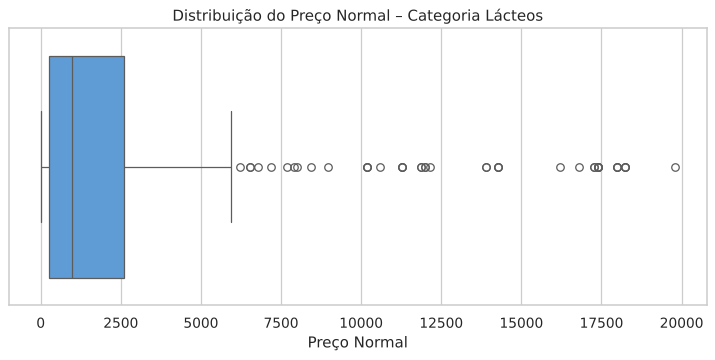

In [8]:
# Filtra apenas a categoria com maior desvio padrão: lacteos
lacteos = df.loc[df['Categoria'] == 'lacteos']

plt.figure(figsize=(10, 4))
sns.boxplot(x=lacteos['Preco_Normal'], color='#4C9BE8')
plt.title('Distribuição do Preço Normal – Categoria Lácteos')
plt.xlabel('Preço Normal')
plt.savefig('grafico1_boxplot_lacteos.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
# Calcula os limites do boxplot (método IQR) e conta os outliers
q1 = lacteos['Preco_Normal'].quantile(0.25)
q3 = lacteos['Preco_Normal'].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
outliers = lacteos[lacteos['Preco_Normal'] > limite_superior]

print(f'Q1: {q1:.0f} | Mediana: {lacteos["Preco_Normal"].median():.0f} | Q3: {q3:.0f} | IQR: {iqr:.0f}')
print(f'Limite superior: {limite_superior:.0f}')
print(f'Quantidade de outliers: {len(outliers)} de {len(lacteos)} produtos ({len(outliers)/len(lacteos):.0%})')
outliers[['title', 'Marca', 'Preco_Normal']].sort_values('Preco_Normal', ascending=False).head(10)

Q1: 269 | Mediana: 989 | Q3: 2609 | IQR: 2340
Limite superior: 6119
Quantidade de outliers: 43 de 447 produtos (10%)


,title,Marca,Preco_Normal
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,17988
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,17988
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,17388
8,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,17388
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,17388


**Leitura do boxplot:**

- A distribuição é **fortemente assimétrica à direita**. A caixa, que concentra 50% dos produtos, fica entre **269 e 2.609**, bem à esquerda do gráfico, e a mediana é **989**.
- **Sim, há muitos outliers:** **43 produtos (cerca de 10% da categoria)** estão acima do limite superior de **6.119**, chegando a **19.788**.
- Esses outliers são, em sua maioria, **packs com várias unidades** (como "Pack 12 un, Leche…") e produtos de maior volume. Não são erros de digitação, e sim outro tipo de produto, vendido em atacado. Por isso fazem sentido no catálogo, mas distorcem a média da categoria.
- O mínimo é 0, porque alguns produtos em promoção têm o preço registrado em Preco_Desconto.

# 4 - Plote um gráfico de barras onde temos a média de descontos por categoria.

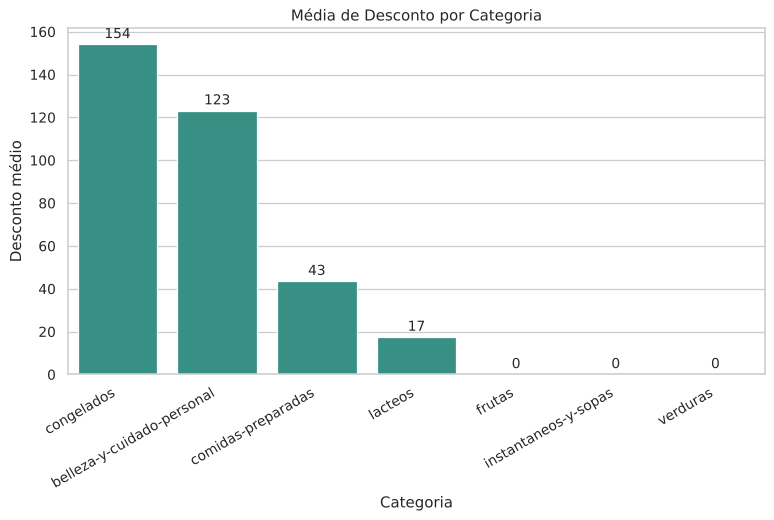

In [10]:
# Média de desconto por categoria, ordenada da maior para a menor
media_desconto = df.groupby('Categoria')['Desconto'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=media_desconto.index, y=media_desconto.values, color='#2A9D8F')
for i, v in enumerate(media_desconto.values):
    ax.text(i, v + 3, f'{v:.0f}', ha='center', fontsize=11)
plt.title('Média de Desconto por Categoria')
plt.xlabel('Categoria')
plt.ylabel('Desconto médio')
plt.xticks(rotation=30, ha='right')
plt.savefig('grafico2_barras_desconto.png', dpi=150, bbox_inches='tight')
plt.show()

**Análise:** **congelados (154)** e **belleza-y-cuidado-personal (123)** têm os maiores descontos médios, seguidos de comidas-preparadas (43) e lacteos (17). **Frutas, verduras e instantaneos-y-sopas não tiveram nenhum desconto** aplicado. As promoções do supermercado se concentram em produtos industrializados de maior valor, e não em hortifrúti.

# 5 - Plote um gráfico de mapa interativo agrupando os dados por categoria, marca e trazendo a média de desconto.

In [11]:
# Agrupa por categoria e marca, calculando a média de desconto
desconto_marca = df.groupby(['Categoria', 'Marca'])['Desconto'].mean().reset_index()

# Mantém só as combinações com desconto (as de desconto zero não teriam área no mapa)
desconto_marca = desconto_marca[desconto_marca['Desconto'] > 0]
desconto_marca.sort_values('Desconto', ascending=False).head(10)

,Categoria,Marca,Desconto
78,congelados,Magnum,955.000000
142,lacteos,Nido,869.800000
39,belleza-y-cuidado-personal,Oral Fresh,797.000000
48,belleza-y-cuidado-personal,Rexona Men Clinical,795.000000
46,belleza-y-cuidado-personal,Rexona Clinical,795.000000
41,belleza-y-cuidado-personal,Pantene,684.857143
47,belleza-y-cuidado-personal,Rexona Men,660.000000
45,belleza-y-cuidado-personal,Rexona,660.000000
79,congelados,Mega,657.000000
6,belleza-y-cuidado-personal,BiO,650.000000


In [ ]:
# Mapa interativo (treemap): o tamanho e a cor de cada bloco representam a média de desconto
fig = px.treemap(desconto_marca,
                 path=[px.Constant('Todas as categorias'), 'Categoria', 'Marca'],
                 values='Desconto',
                 color='Desconto',
                 color_continuous_scale='Teal',
                 title='Média de Desconto por Categoria e Marca')
fig.update_traces(hovertemplate='<b>%{label}</b><br>Desconto médio: %{value:.0f}')
fig.update_layout(margin=dict(t=50, l=10, r=10, b=10))
fig.show()

**Análise:** o mapa mostra que **belleza-y-cuidado-personal** é a categoria com mais marcas em promoção, com destaque para **Oral Fresh, Rexona Clinical e Pantene**. Em **congelados**, a **Magnum** tem o maior desconto médio de toda a base. Em **lacteos**, quem se destaca é a **Nido**. Passando o mouse sobre cada bloco, dá para ver o desconto médio de cada marca.

---
## Conclusões

1. Em quase todas as categorias, a **média de preço fica acima da mediana**. Os preços são assimétricos, com poucos produtos caros puxando a média.
2. **Lacteos** é a categoria mais heterogênea (maior desvio padrão), com **43 outliers**, principalmente packs de 12 unidades.
3. Os **descontos se concentram em congelados e beleza**. Hortifrúti e instantâneos não têm promoções.